This project is on wrangling data from www.retrosheet.org into a dataframe suitable for model building. Specifically, for each game, we will calculate some team stats over their past 162 games.

We will save our dataframe to a file in the enbd. This file will be the starting point for the next notebook, in which we build our first model.

This repo is my "Abhinav Nalluri's" version of what I learned from Brian Luciena's youtube video: https://youtu.be/-e5-Ls4yDRs?list=PLeVfk5xTWHYCCqpcNlbRdIXi2CNt9zKvs
His channel is called "numeristical" and his playlist is called "Baseball Prediction". Special thank to Brian Luciena.

To use this notebook, first download the game logs here: https://www.retrosheet.org/gamelogs/index.html Towards the bottom of the page there are links for ZIP files containing multiple seasons. Download the big zip file for 1871-2025 or zip files for 1980-1989, 1990-1999, ... , 2020-2022, decompress them, and then move all of the single season files to a single directory. You will then need the path to that directory for the variable fname below.

{side note}: I suggest to use 1980 to 2025 because a lot of the older mlb eras may have changed. There is a chance they can either increase or decrease the accuracy of the model. For the sake of brevity, I will first do 1980-2025 and then do 1871-2025 after.

In [54]:
#imports you
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('display.max_columns',1000)
pd.set_option('display.max_rows',1000)

In [55]:
# Fill the path with your data here. Note that you may have to fix the direction of your '\' to '/' when you copy paste the path.
fname = 'C:/Users/themi/source/repos/sports-analytics/MLB-Prediction-modeling/game_data/gl2022.txt'  # This is pulling up the year 2022.
df = pd.read_csv(fname, header=None)

In [56]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160
0,20220407,0,Thu,SDN,NL,1,ARI,NL,1,2,4,51,N,NaN,NaN,NaN,PHO01,35508.0,198,001100000,000000004,29,4,1,0,0,2,0,0,0,7,0,5,1,0,2,0,7,5,4,4,2,0,24,8,0,0,1,0,26,3,0,0,1,3,0,0,1,7,0,6,0,0,1,0,6,6,2,2,0,0,27,9,0,0,2,0,vanol901,Larry Vanover,belld901,Dan Bellino,barbs901,Sean Barber,valej901,Junior Valentine,NaN,(none),NaN,(none),melvb001,Bob Melvin,lovut001,Tony Lovullo,mantj002,Joe Mantiply,suarr002,Robert Suarez,NaN,(none),beers001,Seth Beer,darvy001,Yu Darvish,bumgm001,Madison Bumgarner,nolaa002,Austin Nola,2,machm001,Manny Machado,5,cronj001,Jake Cronenworth,4,voitl001,Luke Voit,10,myerw001,Wil Myers,9,hosme001,Eric Hosmer,3,profj001,Jurickson Profar,7,kim-h002,Ha-Seong Kim,6,grist001,Trent Grisham,8,varsd001,Daulton Varsho,8,martk001,Ketel Marte,4,perad001,David Peralta,7,walkc002,Christian Walker,3,smitp002,Pavin Smith,9,kellc002,Carson Kelly,2,beers001,Seth Beer,10,ellid002,Drew Ellis,5,perdg001,Geraldo Perdomo,6,NaN,Y
1,20220407,0,Thu,CIN,NL,1,ATL,NL,1,6,3,54,N,NaN,NaN,NaN,ATL03,40545.0,181,012003000,001000020,35,10,0,0,1,6,0,1,1,1,0,13,0,0,1,0,5,5,2,2,0,0,27,7,1,0,0,0,31,4,0,0,1,2,0,0,0,5,0,13,0,0,0,0,6,4,6,6,0,0,27,7,0,0,1,0,laynj901,Jerry Layne,wendh902,Hunter Wendelstedt,whitc901,Chad Whitson,hamaa901,Adam Hamari,NaN,(none),NaN,(none),belld002,David Bell,snitb801,Brian Snitker,mahlt001,Tyler Mahle,friem001,Max Fried,santt001,Tony Santillan,farmk001,Kyle Farmer,mahlt001,Tyler Mahle,friem001,Max Fried,indij001,Jonathan India,4,aquia001,Aristides Aquino,9,phamt001,Tommy Pham,7,vottj001,Joey Votto,3,stept001,Tyler Stephenson,2,senzn001,Nick Senzel,8,mousm001,Mike Moustakas,10,farmk001,Kyle Farmer,6,drurb001,Brandon Drury,5,rosae001,Eddie Rosario,9,olsom001,Matt Olson,3,rilea001,Austin Riley,5,ozunm001,Marcell Ozuna,7,albio001,Ozzie Albies,4,duvaa001,Adam Duvall,8,darnt001,Travis d'Arnaud,2,dicka001,Alex Dickerson,10,swand001,Dansby Swanson,6,NaN,Y
2,20220407,0,Thu,MIL,NL,1,CHN,NL,1,4,5,51,D,NaN,NaN,NaN,CHI11,35112.0,198,000100210,00003020x,33,10,4,0,0,4,0,2,1,4,0,9,1,0,2,0,9,3,5,5,0,0,24,10,0,0,1,0,29,8,3,0,1,5,0,1,1,4,0,7,0,1,1,0,6,6,4,4,0,0,27,9,0,0,2,0,barrt901,Ted Barrett,barkl901,Lance Barksdale,lentn901,Nic Lentz,cejan901,Nestor Ceja,NaN,(none),NaN,(none),counc001,Craig Counsell,rossd001,David Ross,givem001,Mychal Givens,ashba003,Aaron Ashby,robed002,David Robertson,happi001,Ian Happ,burnc002,Corbin Burnes,hendk001,Kyle Hendricks,wongk001,Kolten Wong,4,adamw002,Willy Adames,6,yelic001,Christian Yelich,7,mccua001,Andrew McCutchen,10,tellr001,Rowdy Tellez,3,renfh001,Hunter Renfroe,9,narvo001,Omar Narvaez,2,cainl001,Lorenzo Cain,8,petej002,Jace Peterson,5,orter001,Rafael Ortega,10,madrn001,Nick Madrigal,4,contw001,Willson Contreras,2,happi001,Ian Happ,7,schwf001,Frank Schwindel,3,suzus001,Seiya Suzuki,9,heywj001,Jason Heyward,8,wisdp001,Patrick Wisdom,5,hoern001,Nico Hoerner,6,NaN,Y
3,20220407,0,Thu,PIT,NL,1,SLN,NL,1,0,9,51,D,NaN,NaN,NaN,STL10,46256.0,188,000000000,13000104x,30,6,0,0,0,0,0,0,0,2,0,9,0,1,2,0,5,6,9,9,0,0,24,7,2,0,1,0,31,8,2,0,3,9,0,2,1,7,0,5,1,0,1,0,8,4,0,0,1,0,27,11,0,0,3,0,reynj901,Jim Reynolds,ticht901,Todd Tichenor,muchm901,Mike Muchlinski,merzd901,Dan Merzel,NaN,(none),NaN,(none),sheld801,Derek Shelton,marmo801,Oliver Marmol,waina001,Adam Wainwright,brubj001,JT Brubaker,NaN,(none),oneit001,Tyler O'Neill,brubj001,JT Brubaker,waina001,Adam Wainwright,voged001,Daniel Vogelbach,10,reynb001,Bryan Reynolds,8,hayek001,Ke'Bryan Hayes,5,tsuty001,Yoshi Tsutsugo,3,newmk001,Kevin Newman,6,tu

In [57]:
# We got columns we have little clue about. 
# The column that says 'Thu' is probably day of the week and others show what tdivision they are in and the team abbreviation.

# Thankfully, Brian has already made the list for us.

# Get colnames 

In [58]:
colnames = ['date','dblheader_code','day_of_week','team_v','league_v','game_no_v',
           'team_h','league_h','game_no_h', 'runs_v', 'runs_h','outs_total','day_night',
            'completion_info','forfeit_info','protest_info','ballpark_id','attendance','game_minutes',
            'linescore_v','linescore_h',
           'AB_v','H_v','2B_v','3B_v','HR_v','RBI_v','SH_v','SF_v','HBP_v','BB_v','IBB_v','SO_v',
            'SB_v', 'CS_v','GIDP_v','CI_v','LOB_v',
            'P_num_v','ERind_v','ERteam_v','WP_v','balk_v',
            'PO_v','ASST_v','ERR_v','PB_v','DP_v','TP_v',
           'AB_h', 'H_h', '2B_h', '3B_h', 'HR_h', 'RBI_h', 'SH_h', 'SF_h', 'HBP_h', 'BB_h', 'IBB_h','SO_h',
            'SB_h', 'CS_h', 'GIDP_h', 'CI_h', 'LOB_h',
            'P_num_h', 'ERind_h', 'ERteam_h', 'WP_h', 'balk_h',
            'PO_h', 'ASST_h', 'ERR_h', 'PB_h', 'DP_h', 'TP_h',
            'ump_HB_id', 'ump_HB_name','ump_1B_id', 'ump_1B_name','ump_2B_id', 'ump_2B_name',
            'ump_3B_id', 'ump_3B_name','ump_LF_id', 'ump_LF_name','ump_RF_id', 'ump_RF_name',
            'mgr_id_v', 'mgr_name_v', 'mgr_id_h', 'mgr_name_h',
            'pitcher_id_w','pitcher_name_w','pitcher_id_l','pitcher_name_l','pitcher_id_s','pitcher_name_s',
            'GWRBI_id','GWRBI_name','pitcher_start_id_v','pitcher_start_name_v','pitcher_start_id_h','pitcher_start_name_h',
            'batter1_name_v', 'batter1_id_v', 'batter1_pos_v', 'batter2_name_v', 'batter2_id_v', 'batter2_pos_v',
            'batter3_name_v', 'batter3_id_v', 'batter3_pos_v', 'batter4_name_v', 'batter4_id_v', 'batter4_pos_v',
            'batter5_name_v', 'batter5_id_v', 'batter5_pos_v', 'batter6_name_v', 'batter6_id_v', 'batter6_pos_v',
            'batter7_name_v', 'batter7_id_v', 'batter7_pos_v', 'batter8_name_v', 'batter8_id_v', 'batter8_pos_v',
            'batter9_name_v', 'batter9_id_v', 'batter9_pos_v', 'batter1_name_h', 'batter1_id_h', 'batter1_pos_h',
            'batter2_name_h', 'batter2_id_h', 'batter2_pos_h', 'batter3_name_h', 'batter3_id_h', 'batter3_pos_h',
            'batter4_name_h', 'batter4_id_h', 'batter4_pos_h', 'batter5_name_h', 'batter5_id_h', 'batter5_pos_h',
            'batter6_name_h', 'batter6_id_h', 'batter6_pos_h', 'batter7_name_h', 'batter7_id_h', 'batter7_pos_h',
            'batter8_name_h', 'batter8_id_h', 'batter8_pos_h', 'batter9_name_h', 'batter9_id_h', 'batter9_pos_h',           
           'misc_info','acqui_info'
           ]

In [59]:
df.columns = colnames
# we are calling df to read the file and accessing the atribute of colnames to get what matches for column names in the file.

In [60]:
df.sample(10)
# Each row is a game randomly pulled. We pulled 10.

,date,dblheader_code,day_of_week,team_v,league_v,game_no_v,team_h,league_h,game_no_h,runs_v,runs_h,outs_total,day_night,completion_info,forfeit_info,protest_info,ballpark_id,attendance,game_minutes,linescore_v,linescore_h,AB_v,H_v,2B_v,3B_v,HR_v,RBI_v,SH_v,SF_v,HBP_v,BB_v,IBB_v,SO_v,SB_v,CS_v,GIDP_v,CI_v,LOB_v,P_num_v,ERind_v,ERteam_v,WP_v,balk_v,PO_v,ASST_v,ERR_v,PB_v,DP_v,TP_v,AB_h,H_h,2B_h,3B_h,HR_h,RBI_h,SH_h,SF_h,HBP_h,BB_h,IBB_h,SO_h,SB_h,CS_h,GIDP_h,CI_h,LOB_h,P_num_h,ERind_h,ERteam_h,WP_h,balk_h,PO_h,ASST_h,ERR_h,PB_h,DP_h,TP_h,ump_HB_id,ump_HB_name,ump_1B_id,ump_1B_name,ump_2B_id,ump_2B_name,ump_3B_id,ump_3B_name,ump_LF_id,ump_LF_name,ump_RF_id,ump_RF_name,mgr_id_v,mgr_name_v,mgr_id_h,mgr_name_h,pitcher_id_w,pitcher_name_w,pitcher_id_l,pitcher_name_l,pitcher_id_s,pitcher_name_s,GWRBI_id,GWRBI_name,pitcher_start_id_v,pitcher_start_name_v,pitcher_start_id_h,pitcher_start_name_h,batter1_name_v,batter1_id_v,batter1_pos_v,batter2_name_v,batter2_id_v,batter2_pos_v,batter3_name_v,batter3_id_v,batter3_pos_v,batter4_name_v,batter4_id_v,batter4_pos_v,batter5_name_v,batter5_id_v,batter5_pos_v,batter6_name_v,batter6_id_v,batter6_pos_v,batter7_name_v,batter7_id_v,batter7_pos_v,batter8_name_v,batter8_id_v,batter8_pos_v,batter9_name_v,batter9_id_v,batter9_pos_v,batter1_name_h,batter1_id_h,batter1_pos_h,batter2_name_h,batter2_id_h,batter2_pos_h,batter3_name_h,batter3_id_h,batter3_pos_h,batter4_name_h,batter4_id_h,batter4_pos_h,batter5_name_h,batter5_id_h,batter5_pos_h,batter6_name_h,batter6_id_h,batter6_pos_h,batter7_name_h,batter7_id_h,batter7_pos_h,batter8_name_h,batter8_id_h,batter8_pos_h,batter9_name_h,batter9_id_h,batter9_pos_h,misc_info,acqui_info
60,20220412,0,Tue,HOU,AL,5,ARI,NL,5,2,1,54,N,NaN,NaN,NaN,PHO01,17674.0,200,000010001,000001000,34,8,2,0,1,2,0,0,0,5,0,2,0,1,1,0,10,6,1,1,2,0,27,7,0,0,0,0,30,4,1,0,1,1,1,0,0,5,0,7,0,0,0,0,8,6,2,2,0,0,27,8,1,0,1,0,libkj901,John Libka,reynj901,Jim Reynolds,ticht901,Todd Tichenor,muchm901,Mike Muchlinski,NaN,(none),NaN,(none),baked002,Dusty Baker,lovut001,Tony Lovullo,nerih001,Hector Neris,melam001,Mark Melancon,presr001,Ryan Pressly,branm003,Michael Brantley,garcl007,Luis Garcia,bumgm001,Madison Bumgarner,altuj001,Jose Altuve,4,branm003,Michael Brantley,7,brega001,Alex Bregman,5,gurry001,Yulieski Gurriel,3,tuckk001,Kyle Tucker,9,diaza003,Aledmys Diaz,10,penaj004,Jeremy Pena,6,castj006,Jason Castro,2,sirij001,Jose Siri,8,varsd001,Daulton Varsho,8,martk001,Ketel Marte,4,perad001,David Peralta,7,walkc002,Christian Walker,3,smitp002,Pavin Smith,9,beers001,Seth Beer,10,alcas002,Sergio Alcantara,5,perdg001,Geraldo Perdomo,6,herrj003,Jose Herrera,2,NaN,Y
1631,20220808,0,Mon,WAS,NL,111,CHN,NL,108,3,6,51,N,NaN,NaN,NaN,CHI11,30904.0,168,000001020,00300120x,34,8,0,0,2,3,0,0,1,1,0,8,0,1,1,0,6,4,6,6,0,0,24,7,0,0,1,0,31,11,1,0,2,6,1,1,0,4,0,7,2,1,0,0,7,4,3,3,1,0,27,9,1,0,2,0,reynj901,Jim Reynolds,libkj901,John Libka,muchm901,Mike Muchlinski,ramoc901,Charlie Ramos,NaN,(none),NaN,(none),martd002,Dave Martinez,rossd001,David Ross,thomk002,Keegan Thompson,sanca004,Anibal Sanchez,wickr001,Rowan Wick,velan001,Nelson Velazquez,sanca004,Anibal Sanchez,thomk002,Keegan Thompson,roblv001,Victor Robles,8,garcl006,Luis Garcia,6,voitl001,Luke Voit,3,cruzn002,Nelson Cruz,10,herny002,Yadiel Hernandez,7,ruizk001,Keibert Ruiz,2,thoml002,Lane Thomas,9,hernc005,Cesar Hernandez,4,franm004,Maikel Franco,5,orter001,Rafael Ortega,8,contw001,Willson Contreras,2,happi001,Ian Happ,7,suzus001,Seiya Suzuki,9,wisdp001,Patrick Wisdom,3,hoern001,Nico Hoerner,6,velan001,Nelson Velazquez,10,madrn001,Nick Madrigal,4,morec001,Christopher Morel,5,NaN,Y
770,20220603,0,Fri,ANA,AL,53,PHI,NL,52,0,10,51,N,NaN,NaN,NaN,PHI13,28721.0,161,000000000,13004200x,32,5,0,0,0,0,0,0,0,1,0,8,0,0,0,0,6,3,10,10,1,0,24,6,0,0,0,0,34,10,1,1,5,10,0,0,1,3,0,4,0,0,0,0,4,2,0,0,0,0,27,5,0,0,0,0,dejer901,Ramon De Jesus,marqa901,Alfonso Marquez,belld901,Dan Bellino,riggj901,Jeremy Riggs,NaN,(none),NaN,(none),maddj801,Joe Maddon,thomr801,Rob Thomson,efliz001,Zach Efli

In [75]:
# Let's look at each column and understand it
df.sample(1)

,date,dblheader_code,day_of_week,team_v,league_v,game_no_v,team_h,league_h,game_no_h,runs_v,runs_h,outs_total,day_night,completion_info,forfeit_info,protest_info,ballpark_id,attendance,game_minutes,linescore_v,linescore_h,AB_v,H_v,2B_v,3B_v,HR_v,RBI_v,SH_v,SF_v,HBP_v,BB_v,IBB_v,SO_v,SB_v,CS_v,GIDP_v,CI_v,LOB_v,P_num_v,ERind_v,ERteam_v,WP_v,balk_v,PO_v,ASST_v,ERR_v,PB_v,DP_v,TP_v,AB_h,H_h,2B_h,3B_h,HR_h,RBI_h,SH_h,SF_h,HBP_h,BB_h,IBB_h,SO_h,SB_h,CS_h,GIDP_h,CI_h,LOB_h,P_num_h,ERind_h,ERteam_h,WP_h,balk_h,PO_h,ASST_h,ERR_h,PB_h,DP_h,TP_h,ump_HB_id,ump_HB_name,ump_1B_id,ump_1B_name,ump_2B_id,ump_2B_name,ump_3B_id,ump_3B_name,ump_LF_id,ump_LF_name,ump_RF_id,ump_RF_name,mgr_id_v,mgr_name_v,mgr_id_h,mgr_name_h,pitcher_id_w,pitcher_name_w,pitcher_id_l,pitcher_name_l,pitcher_id_s,pitcher_name_s,GWRBI_id,GWRBI_name,pitcher_start_id_v,pitcher_start_name_v,pitcher_start_id_h,pitcher_start_name_h,batter1_name_v,batter1_id_v,batter1_pos_v,batter2_name_v,batter2_id_v,batter2_pos_v,batter3_name_v,batter3_id_v,batter3_pos_v,batter4_name_v,batter4_id_v,batter4_pos_v,batter5_name_v,batter5_id_v,batter5_pos_v,batter6_name_v,batter6_id_v,batter6_pos_v,batter7_name_v,batter7_id_v,batter7_pos_v,batter8_name_v,batter8_id_v,batter8_pos_v,batter9_name_v,batter9_id_v,batter9_pos_v,batter1_name_h,batter1_id_h,batter1_pos_h,batter2_name_h,batter2_id_h,batter2_pos_h,batter3_name_h,batter3_id_h,batter3_pos_h,batter4_name_h,batter4_id_h,batter4_pos_h,batter5_name_h,batter5_id_h,batter5_pos_h,batter6_name_h,batter6_id_h,batter6_pos_h,batter7_name_h,batter7_id_h,batter7_pos_h,batter8_name_h,batter8_id_h,batter8_pos_h,batter9_name_h,batter9_id_h,batter9_pos_h,misc_info,acqui_info,season,run_diff,home_victory,run_total,date_dblhead
579,20030514,0,Wed,KCA,AL,38,MIN,AL,39,0,7,51,N,NaN,NaN,NaN,MIN03,15148.0,145,000000000,10032100x,29,3,0,0,0,0,0,0,1,1,0,2,0,0,2,0,4,3,7,7,0,0,24,12,1,0,0,0,34,12,4,1,1,7,0,1,2,3,0,3,1,1,0,0,9,1,0,0,0,0,27,12,1,0,2,0,bellw901,Wally Bell,welkb901,Bill Welke,danlk901,Kerwin Danley,hirsj901,John Hirschbeck,NaN,(none),NaN,(none),penat001,Tony Pena,gardr001,Ron Gardenhire,reedr002,Rick Reed,hernr003,Runelvys Hernandez,NaN,(none),miend001,Doug Mientkiewicz,hernr003,Runelvys Hernandez,reedr002,Rick Reed,tuckm001,Michael Tucker,9,randj002,Joe Randa,5,beltc001,Carlos Beltran,8,sweem002,Mike Sweeney,10,ibanr001,Raul Ibanez,7,harvk001,Ken Harvey,3,relad001,Desi Relaford,4,maynb001,Brent Mayne,2,berra001,Angel Berroa,6,guzmc001,Cristian Guzman,6,miend001,Doug Mientkiewicz,9,koskc001,Corey Koskie,5,lecrm001,Matt LeCroy,10,huntt001,Torii Hunter,8,seart001,Todd Sears,3,mohrd001,Dustan Mohr,7,piera001,A.J. Pierzynski,2,rival001,Luis Rivas,4,NaN,Y,2003,7,1,7,200305140


It is different each time it is ran. One example of mine was the Tigers vs Royals gives us the id. Date of 9/11/2022. Game was not a double header. Game occurred on a Sunday. The team is the Detroit Tigers. The Tigers are in the AL division and the 'v' means they are visitors. This is game number 140th game of the year for the tigers. The home team is the KC Royals, also in the AL. It is the 141st game for the Royals. Visitors (Tigers) scored no runs. The hometeam (Royals) scored 4. There were 51 outs in total. The game took plays at 'D' for day.

There are more values like hits, umpires, innings, hit by pitfches. The stats for home and away teams exist too. I suggest you look and try on your own.

In [62]:
# For now, we are taking the years of 1980 up to but not including 2025 and then making a for loop.
# This time, we are using fname to choose the folder path and then include a string addition for the number year and then adding .txt to the file name.
# The first pulled file for me is 'C:/Users/themi/source/repos/sports-analytics/MLB-Prediction-modeling/game_data/gl1980.txt'
# read the file and the 
df = pd.DataFrame()
for year in range(1980,2025):
    fname = 'C:/Users/themi/source/repos/sports-analytics/MLB-Prediction-modeling/game_data/gl' +str(year)+'.txt'
    df_temp = pd.read_csv(fname, header= None)
    df_temp.columns = colnames
    df_temp['season'] = year
    df = pd.concat((df, df_temp))

In [63]:
df.shape
# should show there are 101135 games played since 1980 up to but not including 2025 with 162 columns

(101135, 162)

In [64]:
# Check the columns
df.info(max_cols=200)

<class 'pandas.DataFrame'>
Index: 101135 entries, 0 to 2428
Data columns (total 162 columns):
 #    Column                Non-Null Count   Dtype  
---   ------                --------------   -----  
 0    date                  101135 non-null  int64  
 1    dblheader_code        101135 non-null  int64  
 2    day_of_week           101135 non-null  str    
 3    team_v                101135 non-null  str    
 4    league_v              101135 non-null  str    
 5    game_no_v             101135 non-null  int64  
 6    team_h                101135 non-null  str    
 7    league_h              101135 non-null  str    
 8    game_no_h             101135 non-null  int64  
 9    runs_v                101135 non-null  int64  
 10   runs_h                101135 non-null  int64  
 11   outs_total            101135 non-null  int64  
 12   day_night             101135 non-null  str    
 13   completion_info       92 non-null      object 
 14   forfeit_info          1 non-null       object 
 15  

In [65]:
# Create outcomes for columns like the run differential
# Did the home team score more runs?

df['run_diff'] = df['runs_h']-df['runs_v']
df['home_victory'] = (df['run_diff']>0).astype(int)
df['run_total'] = df['runs_h'].copy()+df['runs_v'].copy()
df['date_dblhead'] = (df['date'].astype(str) + df['dblheader_code'].astype(str)).astype(int)

In [66]:
# Try some of your own exploration :)

In [67]:
home_wins = df.home_victory.mean()
print(f"The home team wins about {100*home_wins:.2f}% of the time")

The home team wins about 53.75% of the time


In [68]:
mean_diff = df.run_diff.mean()
print(f"The run differnential per game is about {mean_diff:.2f} runs on average")

The run differnential per game is about 0.12 runs on average


In [69]:
df.run_diff.var() 
# This does not equate to the run differemtial variance per game
# we need to square root this or just get standard deviation


np.float64(18.630257426783146)

In [70]:
stdev_diff = df.run_diff.std()
print(f"In a normally spread distribution, 68% of games have a difference of +/- {stdev_diff:.2f} runs of the mean.")

In a normally spread distribution, 68% of games have a difference of +/- 4.32 runs of the mean.


Run Differential box plot Axes(0.125,0.11;0.775x0.77)

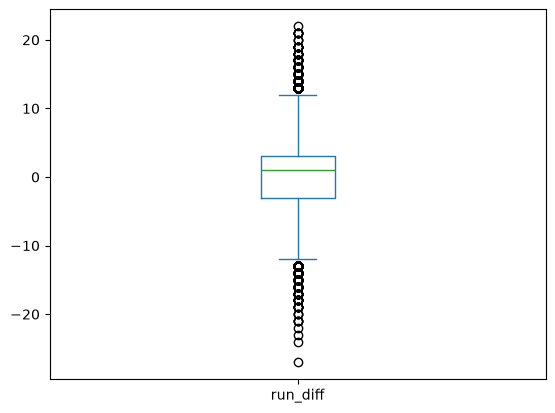

In [71]:
print(f"Run Differential box plot {df.run_diff.plot.box()}")




Big picture - have outcome, need features

* Would like to start simple, base features on team results over past n games  

* Need to do a bit of "data wrangling"
    
* First, we need to have each team's games in chronological order

* Then can use pandas 'rolling' functionality to aggregate over windows in the past
    
* Immediate goal, get batting average, on-base percentage, and slugging       percentage

* Need "running values" based on the past, not including the current game



In [ ]:
# Let's look at how good each team's games. 


In [76]:
df_royals = df.loc[((df.team_v=='KCA') | (df.team_h=='KCA')), :]

In [ ]:
df_royals.shape # we get 7059 games

(7059, 166)

In [ ]:
df_royals.head(100)
# notice it shows when the royals were home team and sometimes when they were the visiting team.

,date,dblheader_code,day_of_week,team_v,league_v,game_no_v,team_h,league_h,game_no_h,runs_v,runs_h,outs_total,day_night,completion_info,forfeit_info,protest_info,ballpark_id,attendance,game_minutes,linescore_v,linescore_h,AB_v,H_v,2B_v,3B_v,HR_v,RBI_v,SH_v,SF_v,HBP_v,BB_v,IBB_v,SO_v,SB_v,CS_v,GIDP_v,CI_v,LOB_v,P_num_v,ERind_v,ERteam_v,WP_v,balk_v,PO_v,ASST_v,ERR_v,PB_v,DP_v,TP_v,AB_h,H_h,2B_h,3B_h,HR_h,RBI_h,SH_h,SF_h,HBP_h,BB_h,IBB_h,SO_h,SB_h,CS_h,GIDP_h,CI_h,LOB_h,P_num_h,ERind_h,ERteam_h,WP_h,balk_h,PO_h,ASST_h,ERR_h,PB_h,DP_h,TP_h,ump_HB_id,ump_HB_name,ump_1B_id,ump_1B_name,ump_2B_id,ump_2B_name,ump_3B_id,ump_3B_name,ump_LF_id,ump_LF_name,ump_RF_id,ump_RF_name,mgr_id_v,mgr_name_v,mgr_id_h,mgr_name_h,pitcher_id_w,pitcher_name_w,pitcher_id_l,pitcher_name_l,pitcher_id_s,pitcher_name_s,GWRBI_id,GWRBI_name,pitcher_start_id_v,pitcher_start_name_v,pitcher_start_id_h,pitcher_start_name_h,batter1_name_v,batter1_id_v,batter1_pos_v,batter2_name_v,batter2_id_v,batter2_pos_v,batter3_name_v,batter3_id_v,batter3_pos_v,batter4_name_v,batter4_id_v,batter4_pos_v,batter5_name_v,batter5_id_v,batter5_pos_v,batter6_name_v,batter6_id_v,batter6_pos_v,batter7_name_v,batter7_id_v,batter7_pos_v,batter8_name_v,batter8_id_v,batter8_pos_v,batter9_name_v,batter9_id_v,batter9_pos_v,batter1_name_h,batter1_id_h,batter1_pos_h,batter2_name_h,batter2_id_h,batter2_pos_h,batter3_name_h,batter3_id_h,batter3_pos_h,batter4_name_h,batter4_id_h,batter4_pos_h,batter5_name_h,batter5_id_h,batter5_pos_h,batter6_name_h,batter6_id_h,batter6_pos_h,batter7_name_h,batter7_id_h,batter7_pos_h,batter8_name_h,batter8_id_h,batter8_pos_h,batter9_name_h,batter9_id_h,batter9_pos_h,misc_info,acqui_info,season,run_diff,home_victory,run_total,date_dblhead
3,19800410,0,Thu,DET,AL,1,KCA,AL,1,5,1,54,N,NaN,NaN,NaN,KAN06,34901.0,148,000103001,001000000,33,9,1,2,2,5,0,0,0,3,0,4,1,1,2,0,4,1,0,0,0,0,27,11,1,0,0,0,31,3,2,0,0,1,0,0,0,3,0,5,1,0,0,0,6,2,4,4,0,1,27,15,1,1,3,0,phild901,Dave Phillips,dimul901,Lou DiMuro,clara901,Al Clark,pales901,Steve Palermo,NaN,(none),NaN,(none),andes101,Sparky Anderson,freyj801,Jim Frey,morrj001,Jack Morris,leond001,Dennis Leonard,NaN,(none),kemps001,Steve Kemp,morrj001,Jack Morris,leond001,Dennis Leonard,whitl001,Lou Whitaker,4,gibsk001,Kirk Gibson,8,kemps001,Steve Kemp,7,hebnr001,Richie Hebner,5,thomj001,Jason Thompson,3,summc001,Champ Summers,10,parrl001,Lance Parrish,2,peter001,Rick Peters,9,wagnm001,Mark Wagner,6,wilsw001,Willie Wilson,8,mcrah001,Hal McRae,10,bretg001,George Brett,5,aikew001,Willie Aikens,3,lacop101,Pete LaCock,7,quirj001,Jamie Quirk,2,hurdc001,Clint Hurdle,9,whitf001,Frank White,4,washu001,U.L. Washington,6,NaN,Y,1980,-4,0,6,198004100
13,19800411,0,Fri,DET,AL,2,KCA,AL,2,0,4,51,N,NaN,NaN,NaN,KAN06,14605.0,133,000000000,00001030x,31,6,0,0,0,0,0,0,0,3,0,5,1,0,1,0,7,2,4,4,0,0,24,11,0,0,0,0,29,7,2,0,0,4,0,0,0,2,1,4,0,1,0,0,3,1,0,0,0,0,27,13,0,0,2,0,dimul901,Lou DiMuro,clara901,Al Clark,pales901,Steve Palermo,phild901,Dave Phillips,NaN,(none),NaN,(none),andes101,Sparky Anderson,freyj801,Jim Frey,gural001,Larry Gura,schad001,Dan Schatzeder,NaN,(none),lacop101,Pete LaCock,schad001,Dan Schatzeder,gural001,Larry Gura,whitl001,Lou Whitaker,4,jonel001,Lynn Jones,9,kemps001,Steve Kemp,7,parrl001,Lance Parrish,2,thomj001,Jason Thompson,3,wockj001,John Wockenfuss,10,broot001,Tom Brookens,5,stegd001,Dave Stegman,8,wagnm001,Mark Wagner,6,wilsw001,Willie Wilson,8,whitf001,Frank White,4,bretg001,George Brett,5,mcrah001,Hal McRae,10,aikew001,Willie Aikens,3,wathj001,John Wathan,2,lacop101,Pete LaCock,7,dethb101,Bob Detherage,9,washu001,U.L. Washington,6,NaN,Y,1980,4,1,4,198004110
25,19800412,0,Sat,DET,AL,3,KCA,AL,3,6,8,51,D,NaN,NaN,NaN,KAN06,16130.0,179,002030100,14100002x,37,10,2,1,0,6,0,0,0,5,0,7,2,0,1,0,9,3,8,8,0,0,24,11,1,0,2,0,36,15,5,3,0,7,0,1,0,1,0,4,3,0,2,0,6,2,5,5,0,0,27,15,2,0,1,0,clara901,Al Clark,pales901,Steve Palermo,phild901,Dave Phillips,dimul901,Lou DiMuro,NaN,(none),NaN,(none),andes101,Sparky Anderson,freyj801,Jim Frey,pattm101,Marty Pattin,

In [79]:
# Helper function
def strip_suffix(x, suff):
    if x.endswith(suff):
        return(x[:-len(suff)])
    else:
        return(x)

visit_cols = [col for col in df.columns if not col.endswith('_h')]
visit_cols_stripped = [strip_suffix(col,'_v') for col in visit_cols]
home_cols = [col for col in df.columns if not col.endswith('_v')]
home_cols_stripped = [strip_suffix(col,'_h') for col in home_cols]

## This subsets the game level df by team, to aggregate team statistics easily
## We also create rolling sums with an offset, so that the rollsum number represents
## statistics up to, but not including, the game in question

def create_team_df(team):
    df_team_v = df[(df.team_v==team)]
    opponent = df_team_v['team_h'] # when we are the visiting team
    df_team_v = df_team_v[visit_cols]
    df_team_v.columns = visit_cols_stripped
    df_team_v['home_game'] = 0
    df_team_v['opponent'] = opponent # give all the visiting columns

    df_team_h = df[(df.team_h==team)] # when we are the home team
    opponent = df_team_h['team_v']
    df_team_h = df_team_h[home_cols]
    df_team_h.columns = home_cols_stripped # give me all the home columns
    df_team_h['home_game'] = 1
    df_team_h['opponent'] = opponent


    df_team = pd.concat((df_team_h, df_team_v)) # concat the home and visitor stats for the team we chose
    df_team.sort_values(['date', 'game_no'],inplace=True)
    
    for winsize in [162,30]: # how many rows in the past (last 162 games)
        suff = str(winsize)
        for raw_col in ['AB','H','2B','3B','HR','BB','runs','SB','CS','ERR']: # which columns we want. HR_r + HR_v for only royals becomes HR
            new_col = 'rollsum_'+raw_col+'_'+suff
            df_team[new_col] = df_team[raw_col].rolling(winsize, closed='left').sum()

        df_team['rollsum_BATAVG_'+suff] = df_team['rollsum_H_'+suff] / df_team['rollsum_AB_'+suff] # column names also gives us hits/at bats for last 162 games
        df_team['rollsum_OBP_'+suff] = (df_team['rollsum_H_'+suff] + df_team['rollsum_BB_'+suff]) / (
                                    df_team['rollsum_AB_'+suff]+df_team['rollsum_BB_'+suff])
        df_team['rollsum_SLG_'+suff] = (df_team['rollsum_H_'+suff] + df_team['rollsum_2B_'+suff] 
                                 + 2*df_team['rollsum_3B_'+suff]+ 
                                3*df_team['rollsum_HR_'+suff] ) / (df_team['rollsum_AB_'+suff])
        df_team['rollsum_OBS_'+suff] = df_team['rollsum_OBP_'+suff] + df_team['rollsum_SLG_'+suff]
    
    df_team['season_game'] = df_team['season']*1000 + df_team['game_no']
    df_team.set_index('season_game', inplace=True)
    return(df_team)

In [82]:
df_royals = create_team_df('KCA') # make it your own team if you wish

In [83]:
df_royals.sample(10)

,date,dblheader_code,day_of_week,team,league,game_no,runs,outs_total,day_night,completion_info,forfeit_info,protest_info,ballpark_id,attendance,game_minutes,linescore,AB,H,2B,3B,HR,RBI,SH,SF,HBP,BB,IBB,SO,SB,CS,GIDP,CI,LOB,P_num,ERind,ERteam,WP,balk,PO,ASST,ERR,PB,DP,TP,ump_HB_id,ump_HB_name,ump_1B_id,ump_1B_name,ump_2B_id,ump_2B_name,ump_3B_id,ump_3B_name,ump_LF_id,ump_LF_name,ump_RF_id,ump_RF_name,mgr_id,mgr_name,pitcher_id_w,pitcher_name_w,pitcher_id_l,pitcher_name_l,pitcher_id_s,pitcher_name_s,GWRBI_id,GWRBI_name,pitcher_start_id,pitcher_start_name,batter1_name,batter1_id,batter1_pos,batter2_name,batter2_id,batter2_pos,batter3_name,batter3_id,batter3_pos,batter4_name,batter4_id,batter4_pos,batter5_name,batter5_id,batter5_pos,batter6_name,batter6_id,batter6_pos,batter7_name,batter7_id,batter7_pos,batter8_name,batter8_id,batter8_pos,batter9_name,batter9_id,batter9_pos,misc_info,acqui_info,season,run_diff,home_victory,run_total,date_dblhead,home_game,opponent,rollsum_AB_162,rollsum_H_162,rollsum_2B_162,rollsum_3B_162,rollsum_HR_162,rollsum_BB_162,rollsum_runs_162,rollsum_SB_162,rollsum_CS_162,rollsum_ERR_162,rollsum_BATAVG_162,rollsum_OBP_162,rollsum_SLG_162,rollsum_OBS_162,rollsum_AB_30,rollsum_H_30,rollsum_2B_30,rollsum_3B_30,rollsum_HR_30,rollsum_BB_30,rollsum_runs_30,rollsum_SB_30,rollsum_CS_30,rollsum_ERR_30,rollsum_BATAVG_30,rollsum_OBP_30,rollsum_SLG_30,rollsum_OBS_30
season_game,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2017074,20170625,0,Sun,KCA,AL,74,2,54,D,NaN,NaN,NaN,KAN06,37182.0,201,100100000,34,9,2,0,1,2,0,0,0,1,0,6,0,0,1,0,6,7,7,7,0,0,27,10,2,0,2,0,tumpj901,John Tumpane,blasc901,Cory Blaser,diazl901,Laz Diaz,westj901,Joe West,NaN,(none),NaN,(none),yoste001,Ned Yost,lirif001,Francisco Liriano,alexs001,Scott Alexander,NaN,(none),bautj002,Jose Bautista,hammj002,Jason Hammel,merrw001,Whit Merrifield,7,bonij002,Jorge Bonifacio,9,cainl001,Lorenzo Cain,8,hosme001,Eric Hosmer,3,peres002,Salvador Perez,10,cuthc001,Cheslor Cuthbert,5,escoa003,Alcides Escobar,6,torrr002,Ramon Torres,4,buted001,Drew Butera,2,NaN,Y,2017,-6,0,10,201706250,1,TOR,5512.0,1361.0,250.0,31.0,169.0,394.0,670.0,109.0,25.0,80.0,0.246916,0.297155,0.395501,0.692656,1030.0,270.0,62.0,6.0,40.0,64.0,145.0,9.0,2.0,13.0,0.262136,0.305302,0.450485,0.755787
1991138,19910910,0,Tue,KCA,AL,138,2,54,N,NaN,NaN,NaN,KAN06,19923.0,177,000000020,35,8,3,0,0,2,0,0,0,5,0,4,0,0,0,0,11,4,7,7,0,1,27,16,1,0,2,0,phild901,Dave Phillips,brinj901,Joe Brinkman,cousd901,Derryl Cousins,hicke901,Ed Hickox,NaN,(none),NaN,(none),mcrah001,Hal McRae,andea001,Allan Anderson,gubim001,Mark Gubicza,aguir001,Rick Aguilera,knobc001,Chuck Knoblauch,gubim001,Mark Gubicza,gibsk001,Kirk Gibson,7,mcrab001,Brian McRae,8,bretg001,George Brett,10,tartd001,Danny Tartabull,9,benzt001,Todd Benzinger,3,pecob001,Bill Pecota,5,pedrj001,Jorge Pedre,2,howad001,David Howard,6,shumt001,Terry Shumpert,4,NaN,Y,1991,-5,0,9,199109100,1,MIN,5576.0,1474.0,296.0,44.0,121.0,494.0,718.0,112.0,69.0,131.0,0.264347,0.324217,0.398314,0.722532,1003.0,241.0,52.0,10.0,18.0,96.0,110.0,17.0,10.0,23.0,0.240279,0.306642,0.365902,0.672545
2008155,20080920,0,Sat,KCA,AL,155,5,51,N,NaN,NaN,NaN,KAN06,23754.0,152,02100020x,34,11,4,0,3,5,0,0,0,0,0,5,0,0,1,0,5,3,2,2,0,0,27,10,0,0,2,0,danlk901,Kerwin Danley,bellw901,Wally Bell,schrp901,Paul Schrieber,diazl901,Laz Diaz,NaN,(none),NaN,(none),hillt801,Trey Hillman,davik002,Kyle Davies,floyg001,Gavin Floyd,sorij001,Joakim Soria,gorda001,Alex Gordon,davik002,Kyle Davies,dejed001,David DeJesus,8,avilm001,Mike Aviles,6,guilj001,Jose Guillen,9,shear001,Ryan Shealy,3,teahm001,Mark Teahen,7,olivm001,Miguel Olivo,2,gorda001,Alex Gordon,5,kaaik001,Kila Ka'aihue,10,calla001,Alberto Callaspo,4,NaN,Y,2008,3,1,7,200809200,1,CHA,5591.0,1485.0,299.0,27.0,116.0,386.0,675.0,81.0,39.0,96.0,0.265605,0.313033,0.390986,0.704019,1038.0,306.0,53.0,8.0,22.0,66.0,143.0,11.0,3.0,17.0,0.294798,0.336957,0.424855,0.761812
2013065,

In [ ]:
# Make a dictionary that maps team level data frame for each team

In [84]:
# Create team level dataframe dictionary for individual teams. Put this in dict for easy access
team_data_dict = {}
for team in df.team_v.unique():
    team_data_dict[team] = create_team_df(team)

In [ ]:
# Go through the rows of the main dataframe, and augment it with home and visiting teams' features

In [86]:
## Create a variety of summarized statistics for each game
## For each game, we look up the home and visiting team in the team
## data dictionary, and then look up the game, and pull the relevant stats
# pandas is not a fan of you adjusting cell by cell, mainly beacuse data frames are in tuples

# These are our feature vectors that are blank
BATAVG_162_h = np.zeros(df.shape[0])
BATAVG_162_v = np.zeros(df.shape[0])
OBP_162_h = np.zeros(df.shape[0])
OBP_162_v = np.zeros(df.shape[0])
SLG_162_h = np.zeros(df.shape[0])
SLG_162_v = np.zeros(df.shape[0])
OBS_162_h = np.zeros(df.shape[0])
OBS_162_v = np.zeros(df.shape[0])
SB_162_h = np.zeros(df.shape[0])
SB_162_v = np.zeros(df.shape[0])
CS_162_h = np.zeros(df.shape[0])
CS_162_v = np.zeros(df.shape[0])
ERR_162_h = np.zeros(df.shape[0])
ERR_162_v = np.zeros(df.shape[0])
BATAVG_30_h = np.zeros(df.shape[0])
BATAVG_30_v = np.zeros(df.shape[0])
OBP_30_h = np.zeros(df.shape[0])
OBP_30_v = np.zeros(df.shape[0])
SLG_30_h = np.zeros(df.shape[0])
SLG_30_v = np.zeros(df.shape[0])
OBS_30_h = np.zeros(df.shape[0])
OBS_30_v = np.zeros(df.shape[0])
SB_30_h = np.zeros(df.shape[0])
SB_30_v = np.zeros(df.shape[0])
CS_30_h = np.zeros(df.shape[0])
CS_30_v = np.zeros(df.shape[0])
ERR_30_h = np.zeros(df.shape[0])
ERR_30_v = np.zeros(df.shape[0])
i=0                                     # Then we iterate through the rows
for index, row in df.iterrows():
    if i%1000==0:
        print(i)
    home_team = row['team_h']
    visit_team = row['team_v']
    game_index_v = row['season']*1000 + row['game_no_v']
    game_index_h = row['season']*1000 + row['game_no_h']
    BATAVG_162_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_BATAVG_162']
    BATAVG_162_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_BATAVG_162']
    OBP_162_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_OBP_162']
    OBP_162_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_OBP_162']
    SLG_162_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_SLG_162']
    SLG_162_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_SLG_162']
    OBS_162_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_OBS_162']
    OBS_162_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_OBS_162']
    SB_162_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_SB_162']
    SB_162_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_SB_162']
    CS_162_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_CS_162']
    CS_162_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_CS_162']
    ERR_162_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_ERR_162']
    ERR_162_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_ERR_162']
    BATAVG_30_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_BATAVG_30']
    BATAVG_30_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_BATAVG_30']
    OBP_30_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_OBP_30']
    OBP_30_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_OBP_30']
    SLG_30_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_SLG_30']
    SLG_30_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_SLG_30']
    OBS_30_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_OBS_30']
    OBS_30_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_OBS_30']
    SB_30_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_SB_30']
    SB_30_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_SB_30']
    CS_30_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_CS_30']
    CS_30_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_CS_30']
    ERR_30_h[i] = team_data_dict[home_team].loc[game_index_h,'rollsum_ERR_30']
    ERR_30_v[i] = team_data_dict[visit_team].loc[game_index_v,'rollsum_ERR_30']
    i+=1
    





0
1000
2000
3000
4000
5000
6000
7000
8000
9000
10000
11000
12000
13000
14000
15000
16000
17000
18000
19000
20000
21000
22000
23000
24000
25000
26000
27000
28000
29000
30000
31000
32000
33000
34000
35000
36000
37000
38000
39000
40000
41000
42000
43000
44000
45000
46000
47000
48000
49000
50000
51000
52000
53000
54000
55000
56000
57000
58000
59000
60000
61000
62000
63000
64000
65000
66000
67000
68000
69000
70000
71000
72000
73000
74000
75000
76000
77000
78000
79000
80000
81000
82000
83000
84000
85000
86000
87000
88000
89000
90000
91000
92000
93000
94000
95000
96000
97000
98000
99000
100000
101000


In [87]:
## We then put the constructed arrays into the main game level dataframe
# putting our variables into dataframes
df['BATAVG_162_h'] = BATAVG_162_h
df['BATAVG_162_v'] = BATAVG_162_v
df['OBP_162_h'] = OBP_162_h
df['OBP_162_v'] = OBP_162_v
df['SLG_162_h'] = SLG_162_h
df['SLG_162_v'] = SLG_162_v
df['OBS_162_h'] = OBS_162_h
df['OBS_162_v'] = OBS_162_v
df['SB_162_h'] = SB_162_h
df['SB_162_v'] = SB_162_v
df['CS_162_h'] = CS_162_h
df['CS_162_v'] = CS_162_v
df['ERR_162_h'] = ERR_162_h
df['ERR_162_v'] = ERR_162_v
df['BATAVG_30_h'] = BATAVG_30_h
df['BATAVG_30_v'] = BATAVG_30_v
df['OBP_30_h'] = OBP_30_h
df['OBP_30_v'] = OBP_30_v
df['SLG_30_h'] = SLG_30_h
df['SLG_30_v'] = SLG_30_v
df['OBS_30_h'] = OBS_30_h
df['OBS_30_v'] = OBS_30_v
df['SB_30_h'] = SB_30_h
df['SB_30_v'] = SB_30_v
df['CS_30_h'] = CS_30_h
df['CS_30_v'] = CS_30_v
df['ERR_30_h'] = ERR_30_h
df['ERR_30_v'] = ERR_30_v



C:\Users\themi\AppData\Local\Temp\ipykernel_4736\1733567802.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['OBS_162_h'] = OBS_162_h
C:\Users\themi\AppData\Local\Temp\ipykernel_4736\1733567802.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['OBS_162_v'] = OBS_162_v
C:\Users\themi\AppData\Local\Temp\ipykernel_4736\1733567802.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once us

In [88]:
df.shape

(101135, 194)

In [89]:
df.sample(5)

,date,dblheader_code,day_of_week,team_v,league_v,game_no_v,team_h,league_h,game_no_h,runs_v,runs_h,outs_total,day_night,completion_info,forfeit_info,protest_info,ballpark_id,attendance,game_minutes,linescore_v,linescore_h,AB_v,H_v,2B_v,3B_v,HR_v,RBI_v,SH_v,SF_v,HBP_v,BB_v,IBB_v,SO_v,SB_v,CS_v,GIDP_v,CI_v,LOB_v,P_num_v,ERind_v,ERteam_v,WP_v,balk_v,PO_v,ASST_v,ERR_v,PB_v,DP_v,TP_v,AB_h,H_h,2B_h,3B_h,HR_h,RBI_h,SH_h,SF_h,HBP_h,BB_h,IBB_h,SO_h,SB_h,CS_h,GIDP_h,CI_h,LOB_h,P_num_h,ERind_h,ERteam_h,WP_h,balk_h,PO_h,ASST_h,ERR_h,PB_h,DP_h,TP_h,ump_HB_id,ump_HB_name,ump_1B_id,ump_1B_name,ump_2B_id,ump_2B_name,ump_3B_id,ump_3B_name,ump_LF_id,ump_LF_name,ump_RF_id,ump_RF_name,mgr_id_v,mgr_name_v,mgr_id_h,mgr_name_h,pitcher_id_w,pitcher_name_w,pitcher_id_l,pitcher_name_l,pitcher_id_s,pitcher_name_s,GWRBI_id,GWRBI_name,pitcher_start_id_v,pitcher_start_name_v,pitcher_start_id_h,pitcher_start_name_h,batter1_name_v,batter1_id_v,batter1_pos_v,batter2_name_v,batter2_id_v,batter2_pos_v,batter3_name_v,batter3_id_v,batter3_pos_v,batter4_name_v,batter4_id_v,batter4_pos_v,batter5_name_v,batter5_id_v,batter5_pos_v,batter6_name_v,batter6_id_v,batter6_pos_v,batter7_name_v,batter7_id_v,batter7_pos_v,batter8_name_v,batter8_id_v,batter8_pos_v,batter9_name_v,batter9_id_v,batter9_pos_v,batter1_name_h,batter1_id_h,batter1_pos_h,batter2_name_h,batter2_id_h,batter2_pos_h,batter3_name_h,batter3_id_h,batter3_pos_h,batter4_name_h,batter4_id_h,batter4_pos_h,batter5_name_h,batter5_id_h,batter5_pos_h,batter6_name_h,batter6_id_h,batter6_pos_h,batter7_name_h,batter7_id_h,batter7_pos_h,batter8_name_h,batter8_id_h,batter8_pos_h,batter9_name_h,batter9_id_h,batter9_pos_h,misc_info,acqui_info,season,run_diff,home_victory,run_total,date_dblhead,BATAVG_162_h,BATAVG_162_v,OBP_162_h,OBP_162_v,SLG_162_h,SLG_162_v,OBS_162_h,OBS_162_v,SB_162_h,SB_162_v,CS_162_h,CS_162_v,ERR_162_h,ERR_162_v,BATAVG_30_h,BATAVG_30_v,OBP_30_h,OBP_30_v,SLG_30_h,SLG_30_v,OBS_30_h,OBS_30_v,SB_30_h,SB_30_v,CS_30_h,CS_30_v,ERR_30_h,ERR_30_v
858,19830622,0,Wed,ATL,NL,68,HOU,NL,70,3,4,52,N,NaN,NaN,NaN,HOU02,25322.0,189,000001002,010010002,33,7,2,0,0,2,0,0,0,4,0,7,3,0,1,0,7,3,3,3,0,0,25,9,2,0,0,0,36,11,2,0,0,3,0,0,0,4,1,7,1,0,0,0,11,3,2,2,0,0,27,10,1,1,1,0,harvd901,Doug Harvey,davib902,Bob Davidson,pullf901,Frank Pulli,dalej901,Jerry Dale,NaN,(none),NaN,(none),torrj101,Joe Torre,lillb101,Bob Lillis,dawlb001,Bill Dawley,garbg001,Gene Garber,NaN,(none),garnp001,Phil Garner,perep001,Pascual Perez,ryann001,Nolan Ryan,butlb001,Brett Butler,7,ramir001,Rafael Ramirez,6,washc001,Claudell Washington,9,murpd001,Dale Murphy,8,chamc001,Chris Chambliss,3,hubbg001,Glenn Hubbard,4,beneb001,Bruce Benedict,2,roysj001,Jerry Royster,5,perep001,Pascual Perez,1,moreo001,Omar Moreno,8,puhlt001,Terry Puhl,9,thond001,Dickie Thon,6,garnp001,Phil Garner,5,cruzj001,Jose Cruz,7,knigr001,Ray Knight,3,reync001,Craig Reynolds,4,pujol001,Luis Pujols,2,ryann001,Nolan Ryan,1,NaN,Y,1983,1,1,7,198306220,0.249727,0.259496,0.307886,0.325179,0.356311,0.384405,0.664197,0.709584,159.0,157.0,88.0,84.0,151.0,147.0,0.249516,0.287390,0.313274,0.346188,0.382979,0.410557,0.696253,0.756746,31.0,26.0,24.0,18.0,25.0,26.0
1054,20020620,0,Thu,MIN,AL,72,NYN,NL,71,2,3,51,N,NaN,NaN,NaN,NYC17,23217.0,163,000000002,00000102x,32,6,1,0,0,2,0,0,0,0,0,8,1,1,0,0,3,4,3,3,0,0,24,7,0,0,0,0,29,6,1,0,2,3,0,0,0,1,0,9,0,1,0,0,3,2,2,2,0,0,27,9,0,0,0,0,gibsg901,Greg Gibson,wintm901,Mike Winters,iassd901,Dan Iassogna,davig901,Gerry Davis,NaN,(none),NaN,(none),gardr001,Ron Gardenhire,valeb102,Bobby Valentine,tracs001,Steve Trachsel,fiort001,Tony Fiore,benia001,Armando Benitez,piazm001,Mike Piazza,milte001,Eric Milton,tracs001,Steve Trachsel,jonej003,Jacque Jones,7,guzmc001,Cristian Guzman,6,miend001,Doug Mientkiewicz,3,koskc001,Corey Koskie,5,huntt001,Torii Hunter,8,kielb001,Bobby Kielty,9,piera001,A.J. Pierzynski,2,rival001,Luis Rivas,4,milte001,Eric Milton,1,alomr001,Roberto Alomar,4,alfoe001,Edgardo Alfonzo,5,piazm001,Mike Piazza,2,valej002,John Valentin,3,paytj001,Jay Payton,

In [90]:
df.to_csv('df_bp1.csv', index=False)

